# Tổng hợp và đánh giá cuối 
Chạy sau: `output/members/vi/` và `output/members/quan/`.

Chọn mô hình bằng CV trước khi nạp test. OOF hậu lựa chọn chỉ phục vụ chẩn đoán. Không sửa mô hình theo kết quả test.

In [1]:
from pathlib import Path
import sys
import pandas as pd
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / 'winequality-red.csv').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Đặt notebook trong thư mục notebooks của dự án.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
OUT = PROJECT_ROOT / 'output'


## 1. Tổng hợp kết quả 
Kiểm tra cùng dữ liệu, Pipeline, phiên bản scikit-learn, fold và ngân sách tìm kiếm; xếp hạng tất cả cấu hình theo F1 macro CV. Sau khi chốt mới đánh giá test. Ô sau chỉ chạy lần đầu.

In [3]:
import json
import pandas as pd
from IPython.display import display

required_files = [
    "initial_cv_results.csv",
    "tuned_cv_results.csv",
    "selection_decision.json",
    "test_metrics.json",
    "test_classification_report.csv",
    "final_pipeline.joblib"
]

missing = [
    name for name in required_files
    if not (OUT / name).exists()
]

if missing:
    print("Lần chạy trước có thể chưa hoàn tất. Thiếu:")
    for name in missing:
        print("-", name)
else:
    initial = pd.read_csv(OUT / "initial_cv_results.csv")
    tuned = pd.read_csv(OUT / "tuned_cv_results.csv")

    decision = json.loads(
        (OUT / "selection_decision.json").read_text(encoding="utf-8")
    )
    test_metrics = json.loads(
        (OUT / "test_metrics.json").read_text(encoding="utf-8")
    )

    print("KẾT QUẢ CV BAN ĐẦU")
    display(initial.round(4))

    print("KẾT QUẢ TÌM SIÊU THAM SỐ")
    display(tuned.round(4))

    print("QUYẾT ĐỊNH CHỌN MÔ HÌNH")
    display(pd.DataFrame([decision]))

    print("KẾT QUẢ TRÊN TẬP KIỂM TRA")
    display(pd.DataFrame([test_metrics]).round(4))

KẾT QUẢ CV BAN ĐẦU


,model,train_accuracy_mean,train_accuracy_std,val_accuracy_mean,val_accuracy_std,train_balanced_accuracy_mean,train_balanced_accuracy_std,val_balanced_accuracy_mean,val_balanced_accuracy_std,train_f1_macro_mean,train_f1_macro_std,val_f1_macro_mean,val_f1_macro_std,train_f1_weighted_mean,train_f1_weighted_std,val_f1_weighted_mean,val_f1_weighted_std,fit_time_mean
0,Dummy most_frequent,0.4366,0.0001,0.4366,0.0006,0.3333,0.0000,0.3333,0.0000,0.2026,0.0000,0.2026,0.0002,0.2653,0.0002,0.2653,0.0006,0.0067
1,Dummy stratified,0.3704,0.0017,0.3614,0.0200,0.3349,0.0025,0.3241,0.0217,0.3349,0.0026,0.3236,0.0222,0.3688,0.0017,0.3590,0.0204,0.0079
2,Logistic Regression,0.5926,0.0053,0.5860,0.0140,0.5499,0.0069,0.5424,0.0132,0.5617,0.0071,0.5540,0.0144,0.5872,0.0060,0.5801,0.0143,0.0245
3,Decision Tree,1.0000,0.0000,0.5266,0.0160,1.0000,0.0000,0.5131,0.0152,1.0000,0.0000,0.5123,0.0150,1.0000,0.0000,0.5276,0.0153,0.0324
4,Bagging,1.0000,0.0000,0.6149,0.0176,1.0000,0.0000,0.5848,0.0132,1.0000,0.0000,0.5956,0.0142,1.0000,0.0000,0.6125,0.0169,1.6592
5,Random Forest,1.0000,0.0000,0.6316,0.0167,1.0000,0.0000,0.5970,0.0157,1.0000,0.0000,0.6099,0.0168,1.0000,0.0000,0.6284,0.0163,0.5585
6,Extra Trees,1.0000,0.0000,0.6382,0.0149,1.0000,0.0000,0.6016,0.0155,1.0000,0.0000,0.6140,0.0174,1.0000,0.0000,0.6342,0.0152,0.3765


KẾT QUẢ TÌM SIÊU THAM SỐ


,model,stage,f1_macro,std,train_f1_macro,best_params
0,Decision Tree,tuned,0.5271,0.0165,0.7751,"{'model__min_samples_leaf': 1, 'model__max_dep..."
1,Bagging,tuned,0.6011,0.0135,0.9996,"{'model__n_estimators': 200, 'model__max_sampl..."
2,Random Forest,tuned,0.6128,0.0149,0.9587,"{'model__n_estimators': 200, 'model__min_sampl..."
3,Extra Trees,tuned,0.6132,0.0138,1.0000,"{'model__n_estimators': 100, 'model__min_sampl..."


QUYẾT ĐỊNH CHỌN MÔ HÌNH


,model,selection_metric,selection_cv_mean,selection_cv_std,n_iter,random_state
0,Extra Trees,f1_macro,0.61395,0.017353,8,42


KẾT QUẢ TRÊN TẬP KIỂM TRA


,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,0.6024,0.5752,0.5876,0.5998


## 2. Đọc lại kết quả đã lưu
Có thể chạy lại phần này mà không huấn luyện hay đánh giá test lại.

In [4]:
import json
display(pd.read_csv(OUT/'selection_cv_results.csv'))
print(json.loads((OUT/'test_metrics.json').read_text()))
display(pd.read_csv(OUT / 'test_classification_report.csv', index_col=0))
display(pd.read_csv(OUT / 'oof_group_metrics.csv'))
display(pd.read_csv(OUT / 'permutation_importance.csv'))
display(pd.read_csv(OUT / 'test_error_examples.csv').head(10))


,model,stage,f1_macro,std
0,Extra Trees,initial,0.613950,0.017353
1,Extra Trees tuned,tuned,0.613218,0.013822
2,Random Forest tuned,tuned,0.612789,0.014874
3,Random Forest,initial,0.609857,0.016808
4,Bagging tuned,tuned,0.601064,0.013465
5,Bagging,initial,0.595644,0.014157
6,Logistic Regression,initial,0.554022,0.014397
7,Decision Tree tuned,tuned,0.527052,0.016549
8,Decision Tree,initial,0.512345,0.014984
9,Dummy stratified,initial,0.323582,0.022188


{'accuracy': 0.6024436090225563, 'balanced_accuracy': 0.5751505109071076, 'f1_macro': 0.5875548044743214, 'f1_weighted': 0.599839398570339}


,precision,recall,f1-score,support
Thấp,0.656250,0.687657,0.671587,397.000000
Trung bình,0.550098,0.602151,0.574949,465.000000
Cao,0.633094,0.435644,0.516129,202.000000
accuracy,0.602444,0.602444,0.602444,0.602444
macro avg,0.613147,0.575151,0.587555,1064.000000
weighted avg,0.605462,0.602444,0.599839,1064.000000


,group,n,accuracy,balanced_accuracy,f1_macro,f1_weighted
0,all,4256,0.638158,0.601576,0.614059,0.634341
1,red,1106,0.649186,0.560430,0.574481,0.638261
2,white,3150,0.634286,0.604739,0.617580,0.631226


,feature,mean,std
0,alcohol,0.156746,0.017064
1,volatile acidity,0.050876,0.015811
2,total sulfur dioxide,0.038859,0.013648
3,wine_type_white,0.037095,0.011145
4,density,0.037094,0.016696
5,free sulfur dioxide,0.032460,0.017116
6,sulphates,0.030453,0.012738
7,chlorides,0.023541,0.014933
8,residual sugar,0.020071,0.008984
9,citric acid,0.016980,0.009213


,clean_row_id,wine_type,quality,true_label,pred_label,correct,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type_white
0,2415,white,7,2,1,False,5.3,0.26,0.23,5.15,0.034,48.0,160.0,0.99520,3.82,0.51,10.5,1
1,3863,white,5,0,1,False,7.7,0.18,0.53,1.20,0.041,42.0,167.0,0.99080,3.11,0.44,11.9,1
2,3803,white,5,0,1,False,8.4,0.31,0.31,0.95,0.021,52.0,148.0,0.99038,2.93,0.32,11.5,1
3,4107,white,6,1,2,False,6.0,0.22,0.28,1.10,0.034,47.0,90.0,0.98862,3.22,0.38,12.6,1
4,418,red,6,1,2,False,10.4,0.24,0.49,1.80,0.075,6.0,20.0,0.99770,3.18,1.06,11.0,0
5,3867,white,7,2,1,False,5.6,0.20,0.66,10.20,0.043,78.0,175.0,0.99450,2.98,0.43,10.4,1
6,4231,white,6,1,2,False,6.3,0.21,0.31,1.20,0.043,30.0,117.0,0.99158,3.49,0.68,11.0,1
7,2681,white,6,1,0,False,7.4,0.30,0.49,8.20,0.055,49.0,188.0,0.99740,3.52,0.58,9.7,1
8,2752,white,4,0,1,False,8.2,0.29,0.49,1.00,0.044,29.0,118.0,0.99280,3.24,0.36,10.9,1
9,1783,white,7,2,1,False,6.0,0.24,0.27,1.90,0.048,40.0,170.0,0.99380,3.64,0.54,10.0,1


## 3. Biểu đồ kết quả

### So sánh kết quả CV ban đầu

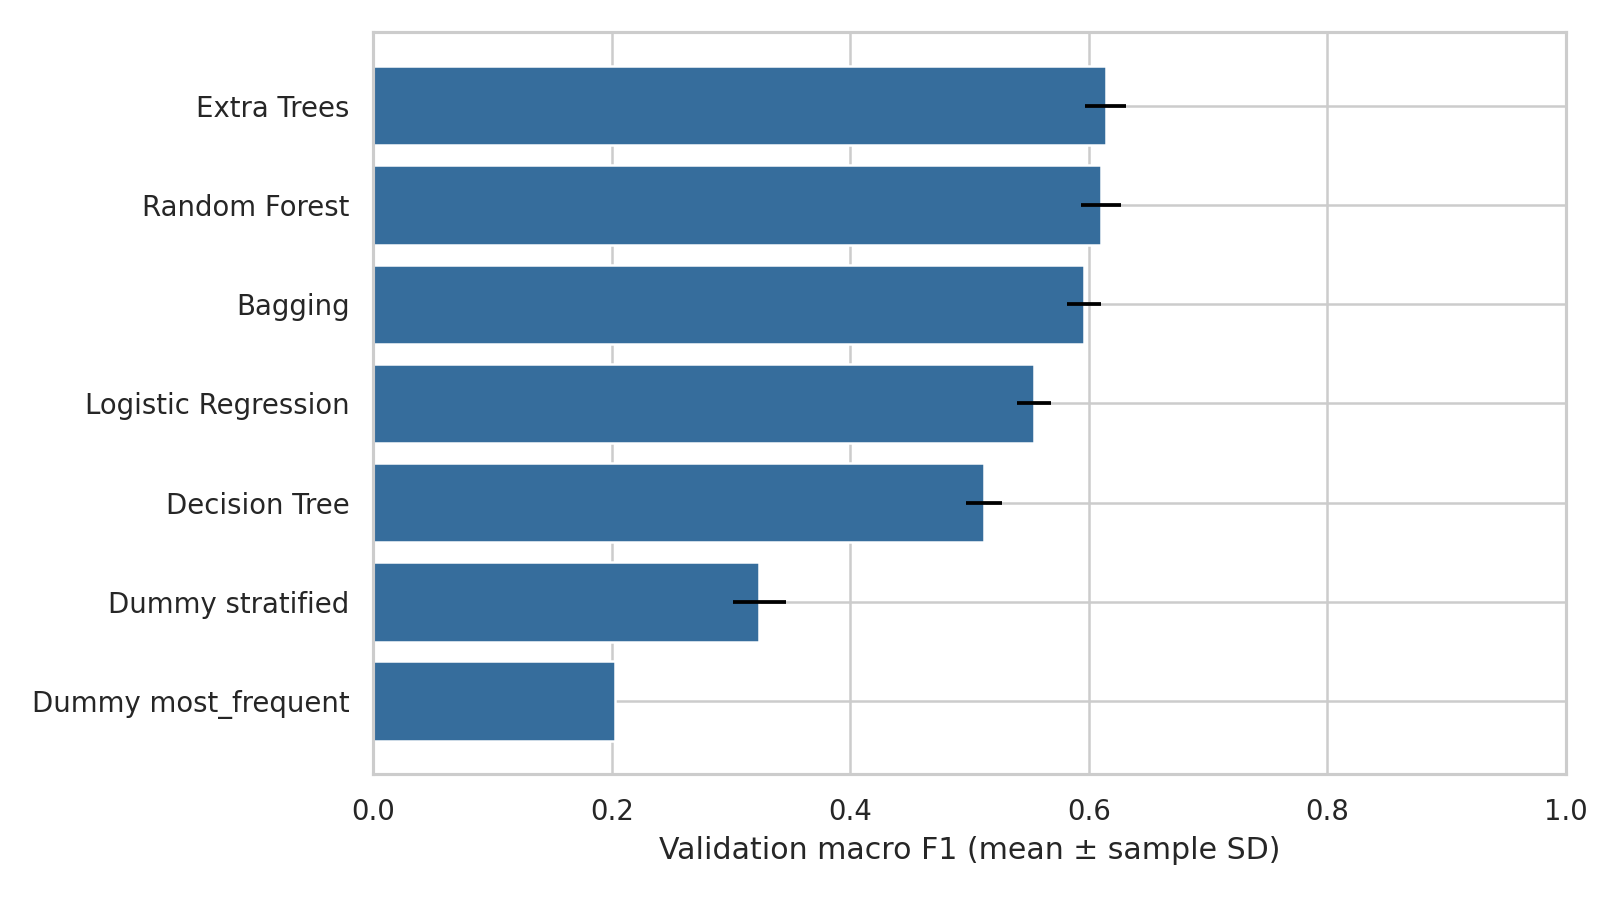

### Ma trận nhầm lẫn trên tập kiểm tra

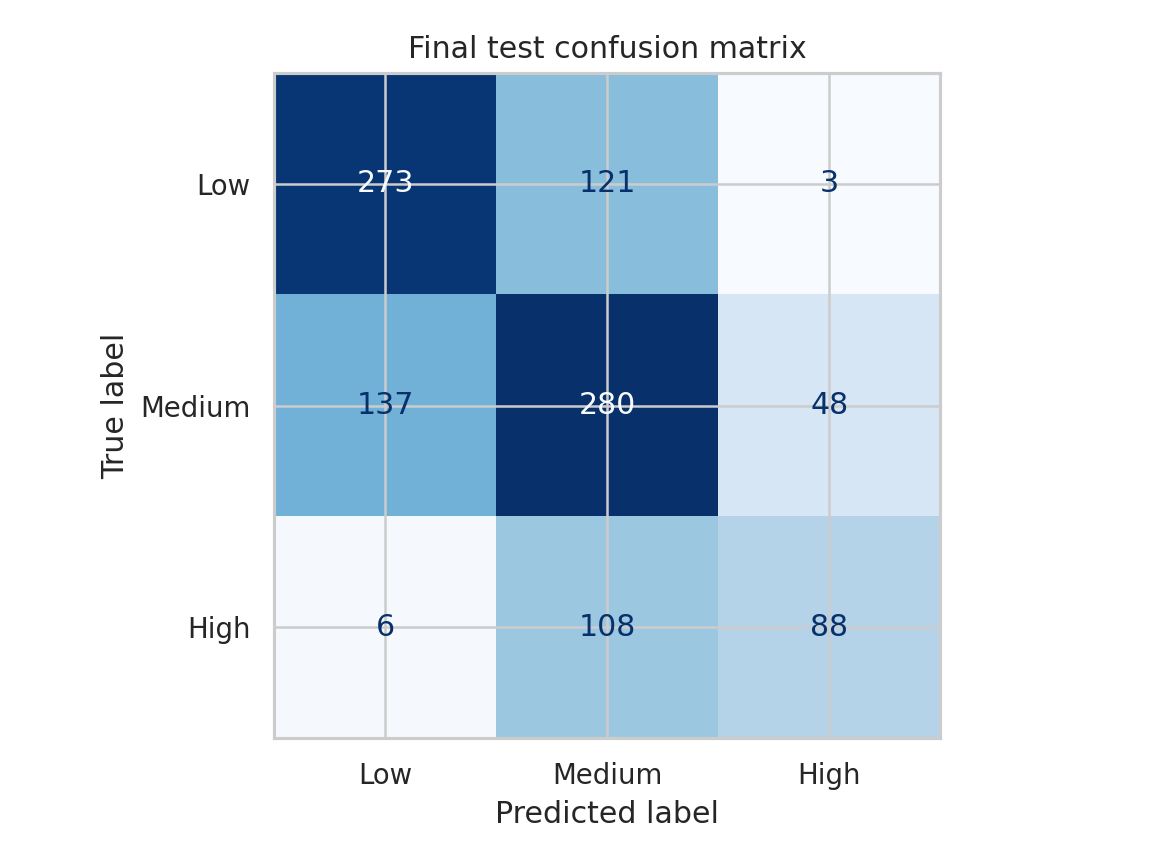

### Ma trận nhầm lẫn theo tỷ lệ

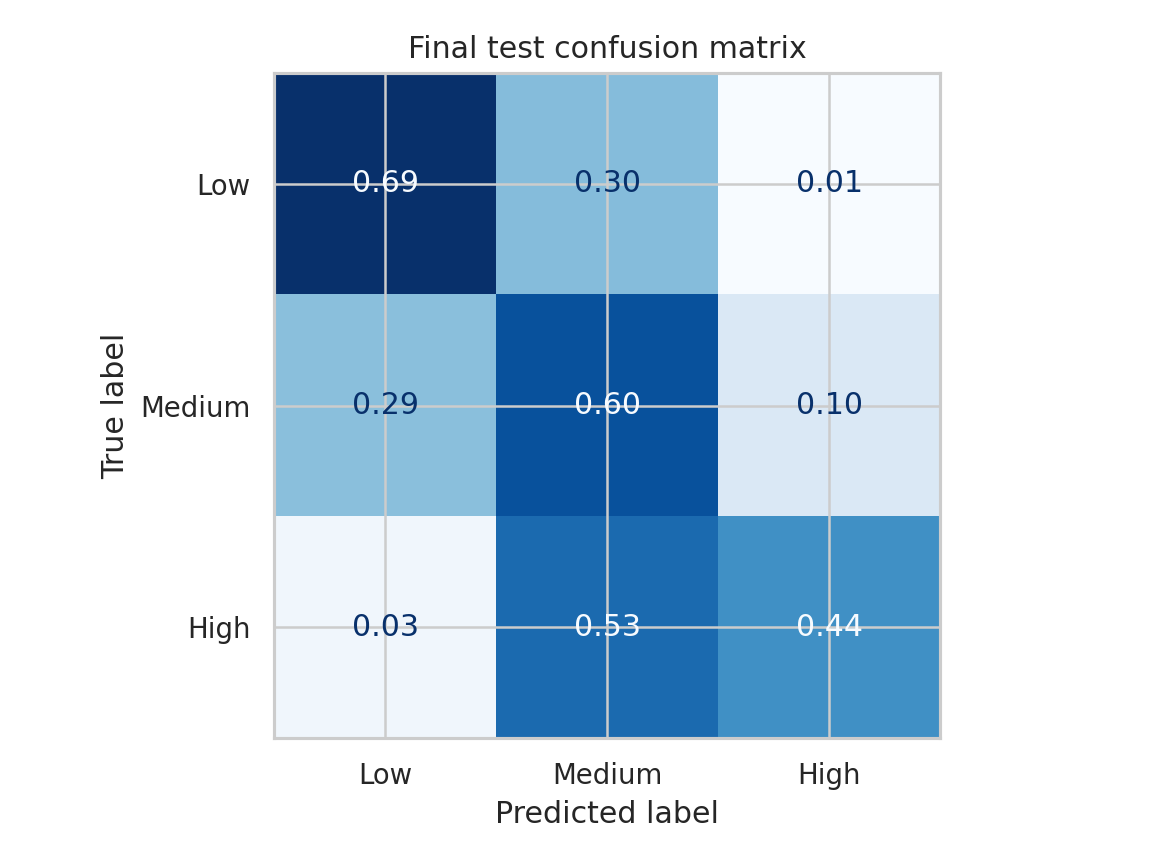

### Độ quan trọng đặc trưng theo hoán vị

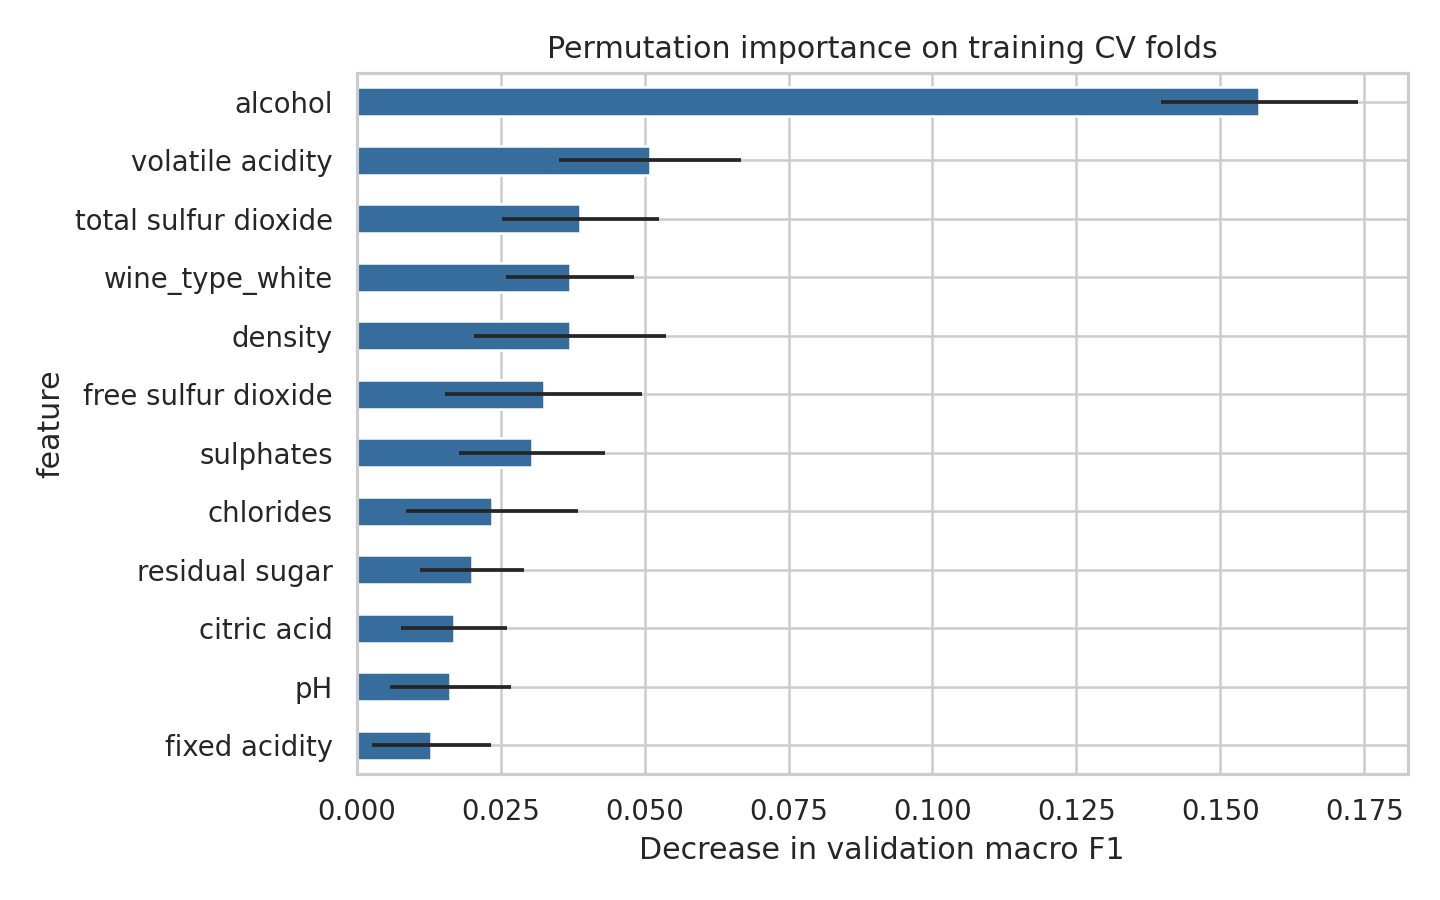

In [6]:
from IPython.display import display, Image, Markdown

figures = {
    "initial_cv_comparison": "So sánh kết quả CV ban đầu",
    "test_confusion_matrix": "Ma trận nhầm lẫn trên tập kiểm tra",
    "test_confusion_matrix_normalized": "Ma trận nhầm lẫn theo tỷ lệ",
    "permutation_importance": "Độ quan trọng đặc trưng theo hoán vị"
}

for name, title in figures.items():
    path = OUT / "figures" / f"{name}.png"

    display(Markdown(f"### {title}"))

    if path.exists():
        display(Image(filename=str(path), width=850))
    else:
        print(f"Chưa tìm thấy ảnh: {path.name}")


## 4. Phân tích quá khớp và độ quan trọng
So sánh F1 macro train và validation; đọc độ quan trọng impurity nếu mô hình hỗ trợ. Quân phối hợp giải thích kết quả.

In [7]:
cv = pd.read_csv(OUT/'initial_cv_results.csv')
cv['gap_f1_macro'] = cv['train_f1_macro_mean'] - cv['val_f1_macro_mean']
display(cv[['model','train_f1_macro_mean','val_f1_macro_mean','gap_f1_macro']])
if (OUT/'impurity_importance.csv').exists():
    display(pd.read_csv(OUT/'impurity_importance.csv'))

,model,train_f1_macro_mean,val_f1_macro_mean,gap_f1_macro
0,Dummy most_frequent,0.202595,0.202595,6.265185e-08
1,Dummy stratified,0.334870,0.323582,1.128763e-02
2,Logistic Regression,0.561710,0.554022,7.687718e-03
3,Decision Tree,1.000000,0.512345,4.876554e-01
4,Bagging,1.000000,0.595644,4.043558e-01
5,Random Forest,1.000000,0.609857,3.901428e-01
6,Extra Trees,1.000000,0.613950,3.860497e-01


,Unnamed: 0,importance
0,alcohol,0.148963
1,volatile acidity,0.100280
2,density,0.094234
3,total sulfur dioxide,0.085951
4,free sulfur dioxide,0.085621
5,sulphates,0.083383
6,chlorides,0.080400
7,citric acid,0.079286
8,residual sugar,0.078783
9,pH,0.077469


## 4 Khảo sát OOB bổ trợ
Chỉ khảo sát Bagging và Random Forest với 100 cây trên train. Kết quả không dùng thay đổi mô hình đã chốt và không truy cập test. Extra Trees cuối dùng bootstrap=False nên không có OOB.

In [9]:
import numpy as np
import pandas as pd
from IPython.display import display

from src.pipelines import model_pipelines
from src.evaluation import metrics

# Chỉ sử dụng dữ liệu huấn luyện
X_oob = pd.read_csv(OUT / "X_train.csv")
y_oob = pd.read_csv(OUT / "y_train.csv")["label"]

initial_cv = pd.read_csv(
    OUT / "initial_cv_results.csv"
).set_index("model")

# Khảo sát cấu hình ban đầu, không thay đổi mô hình đã chọn
models = model_pipelines()
oob_rows = []

for name in ["Bagging", "Random Forest"]:
    print(f"Đang khảo sát OOB: {name}...")

    pipe = models[name]
    pipe.set_params(
        model__bootstrap=True,
        model__oob_score=True
    )
    pipe.fit(X_oob, y_oob)

    model = pipe.named_steps["model"]
    probabilities = model.oob_decision_function_

    # Chỉ tính điểm cho mẫu có dự đoán OOB hợp lệ
    valid = (
        np.isfinite(probabilities).all(axis=1)
        & (probabilities.sum(axis=1) > 0)
    )

    if not valid.any():
        raise ValueError(f"{name}: không có dự đoán OOB hợp lệ.")

    predictions = model.classes_[
        probabilities[valid].argmax(axis=1)
    ]

    scores = metrics(
        y_oob.to_numpy()[valid],
        predictions
    )

    oob_rows.append({
        "model": name,
        "n_valid": int(valid.sum()),
        "oob_accuracy": scores["accuracy"],
        "oob_f1_macro": scores["f1_macro"],
        "cv_accuracy": initial_cv.loc[name, "val_accuracy_mean"],
        "cv_f1_macro": initial_cv.loc[name, "val_f1_macro_mean"]
    })

# Lưu kết quả gốc
oob_results = pd.DataFrame(oob_rows)
oob_results.to_csv(OUT / "oob_results.csv", index=False)

# Hiển thị bảng dễ đọc
table = oob_results.rename(columns={
    "model": "Mô hình",
    "n_valid": "Số mẫu OOB hợp lệ",
    "oob_accuracy": "Accuracy OOB",
    "oob_f1_macro": "F1 macro OOB",
    "cv_accuracy": "Accuracy CV",
    "cv_f1_macro": "F1 macro CV"
})

print("\nKẾT QUẢ KHẢO SÁT OOB")
display(
    table.style
    .hide(axis="index")
    .format({
        "Số mẫu OOB hợp lệ": "{:,.0f}",
        "Accuracy OOB": "{:.4f}",
        "F1 macro OOB": "{:.4f}",
        "Accuracy CV": "{:.4f}",
        "F1 macro CV": "{:.4f}"
    })
)


Đang khảo sát OOB: Bagging...
Đang khảo sát OOB: Random Forest...

KẾT QUẢ KHẢO SÁT OOB


Mô hình,Số mẫu OOB hợp lệ,Accuracy OOB,F1 macro OOB,Accuracy CV,F1 macro CV
Bagging,"4,256",0.6161,0.5962,0.6149,0.5956
Random Forest,"4,256",0.6273,0.6041,0.6316,0.6099


## 5. Kết quả dự đoán trên tập kiểm tra

Hiển thị nhãn thực tế và nhãn dự đoán của 20 mẫu đầu tiên trong tập kiểm tra.

In [10]:
display(pd.read_csv(OUT / "test_predictions.csv").head(20))

,clean_row_id,wine_type,quality,true_label,pred_label,correct,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,wine_type_white
0,3299,white,8,2,2,True,7.7,0.40,0.27,4.50,0.034,27.0,95.0,0.99175,3.21,0.59,12.3,1
1,2415,white,7,2,1,False,5.3,0.26,0.23,5.15,0.034,48.0,160.0,0.99520,3.82,0.51,10.5,1
2,5230,white,6,1,1,True,6.2,0.26,0.20,8.00,0.047,35.0,111.0,0.99445,3.11,0.42,10.4,1
3,3052,white,5,0,0,True,6.4,0.26,0.40,1.70,0.179,5.0,60.0,0.99250,3.09,0.54,10.1,1
4,3863,white,5,0,1,False,7.7,0.18,0.53,1.20,0.041,42.0,167.0,0.99080,3.11,0.44,11.9,1
5,3803,white,5,0,1,False,8.4,0.31,0.31,0.95,0.021,52.0,148.0,0.99038,2.93,0.32,11.5,1
6,4107,white,6,1,2,False,6.0,0.22,0.28,1.10,0.034,47.0,90.0,0.98862,3.22,0.38,12.6,1
7,367,red,5,0,0,True,6.8,0.77,0.00,1.80,0.066,34.0,52.0,0.99760,3.62,0.68,9.9,0
8,418,red,6,1,2,False,10.4,0.24,0.49,1.80,0.075,6.0,20.0,0.99770,3.18,1.06,11.0,0
9,3867,white,7,2,1,False,5.6,0.20,0.66,10.20,0.043,78.0,175.0,0.99450,2.98,0.43,10.4,1


In [11]:
import sys
import platform
import os
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import joblib

environment = {
    "Hệ điều hành": platform.platform(),
    "Python": sys.version.split()[0],
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "Matplotlib": matplotlib.__version__,
    "joblib": joblib.__version__,
    "Bộ xử lý": platform.processor() or "Không xác định",
    "Số CPU logic": os.cpu_count()
}

display(pd.DataFrame(
    environment.items(),
    columns=["Thành phần", "Phiên bản / cấu hình"]
))

,Thành phần,Phiên bản / cấu hình
0,Hệ điều hành,Windows-11-10.0.26200-SP0
1,Python,3.13.5
2,NumPy,2.1.3
3,pandas,2.2.3
4,scikit-learn,1.6.1
5,Matplotlib,3.10.0
6,joblib,1.4.2
7,Bộ xử lý,"Intel64 Family 6 Model 186 Stepping 2, Genuine..."
8,Số CPU logic,16
